## Seattle vs Miami Precipitation Analysis


## Introduction

I wanted to do an investigation to compare precipitation patters between Seattle and Miami. I decided to investigate Miami because I was interested in whether South Florida's hurricane and wet seasons would result in Miami receiving more rainfall than Seattle.

The goal of this analysis is to determine whether it rains more in Seattle or Miami by comparing both the amount of precipitation and how frequently precipitation occurs.

In [447]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

In [448]:
df_seattle = pd.read_csv('/Users/hakimmacbook/Desktop/Foundations of Data Science 5100/Weather/Data/seattle_rain.csv')

type(df_seattle)

pandas.DataFrame

In [449]:
df_seattle.head()

,STATION,NAME,DATE,DAPR,MDPR,PRCP,SNOW,SNWD,WESD,WESF
0,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/1/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
1,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/2/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
2,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/3/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
3,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/4/18,NaN,NaN,0.00,NaN,NaN,NaN,NaN
4,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",1/5/18,NaN,NaN,0.25,NaN,NaN,NaN,NaN


In [450]:
df_seattle.columns

Index(['STATION', 'NAME', 'DATE', 'DAPR', 'MDPR', 'PRCP', 'SNOW', 'SNWD',
       'WESD', 'WESF'],
      dtype='str')

In [451]:
df_miami = pd.read_csv('/Users/hakimmacbook/Desktop/Foundations of Data Science 5100/Weather/Data/miami_rain.csv')
type(df_miami)

pandas.DataFrame

In [452]:
df_miami.head()

,STATION,NAME,DATE,DAPR,MDPR,PRCP
0,USW00092811,"MIAMI BEACH, FL US",2018-01-01,NaN,NaN,0.0
1,USW00092811,"MIAMI BEACH, FL US",2018-01-02,NaN,NaN,0.0
2,USW00092811,"MIAMI BEACH, FL US",2018-01-03,NaN,NaN,1.5
3,USW00092811,"MIAMI BEACH, FL US",2018-01-04,NaN,NaN,0.1
4,USW00092811,"MIAMI BEACH, FL US",2018-01-05,NaN,NaN,0.0


In [453]:
df_miami.columns

Index(['STATION', 'NAME', 'DATE', 'DAPR', 'MDPR', 'PRCP'], dtype='str')

In [454]:
df_seattle.info

<bound method DataFrame.info of           STATION                    NAME      DATE  DAPR  MDPR  PRCP  SNOW  \
0     US1WAKG0225  SEATTLE 2.1 ESE, WA US    1/1/18   NaN   NaN  0.00   NaN   
1     US1WAKG0225  SEATTLE 2.1 ESE, WA US    1/2/18   NaN   NaN  0.00   NaN   
2     US1WAKG0225  SEATTLE 2.1 ESE, WA US    1/3/18   NaN   NaN  0.00   NaN   
3     US1WAKG0225  SEATTLE 2.1 ESE, WA US    1/4/18   NaN   NaN  0.00   NaN   
4     US1WAKG0225  SEATTLE 2.1 ESE, WA US    1/5/18   NaN   NaN  0.25   NaN   
...           ...                     ...       ...   ...   ...   ...   ...   
1653  US1WAKG0225  SEATTLE 2.1 ESE, WA US  12/27/22   NaN   NaN  0.78   NaN   
1654  US1WAKG0225  SEATTLE 2.1 ESE, WA US  12/28/22   NaN   NaN  0.40   NaN   
1655  US1WAKG0225  SEATTLE 2.1 ESE, WA US  12/29/22   NaN   NaN  0.03   NaN   
1656  US1WAKG0225  SEATTLE 2.1 ESE, WA US  12/30/22   NaN   NaN  0.62   NaN   
1657  US1WAKG0225  SEATTLE 2.1 ESE, WA US  12/31/22   NaN   NaN  0.17   NaN   

      SNWD  WESD  W

In [455]:
df_miami.info

<bound method DataFrame.info of           STATION                NAME        DATE  DAPR  MDPR  PRCP
0     USW00092811  MIAMI BEACH, FL US  2018-01-01   NaN   NaN  0.00
1     USW00092811  MIAMI BEACH, FL US  2018-01-02   NaN   NaN  0.00
2     USW00092811  MIAMI BEACH, FL US  2018-01-03   NaN   NaN  1.50
3     USW00092811  MIAMI BEACH, FL US  2018-01-04   NaN   NaN  0.10
4     USW00092811  MIAMI BEACH, FL US  2018-01-05   NaN   NaN  0.00
...           ...                 ...         ...   ...   ...   ...
1593  USW00092811  MIAMI BEACH, FL US  2022-12-27   NaN   NaN  0.15
1594  USW00092811  MIAMI BEACH, FL US  2022-12-28   NaN   NaN  0.00
1595  USW00092811  MIAMI BEACH, FL US  2022-12-29   NaN   NaN  0.00
1596  USW00092811  MIAMI BEACH, FL US  2022-12-30   NaN   NaN  0.00
1597  USW00092811  MIAMI BEACH, FL US  2022-12-31   NaN   NaN  0.00

[1598 rows x 6 columns]>

In [456]:
print(df_seattle.shape)

(1658, 10)


In [457]:
print(df_miami.shape)

(1598, 6)


In [458]:
df_miami['STATION']

0       USW00092811
1       USW00092811
2       USW00092811
3       USW00092811
4       USW00092811
           ...     
1593    USW00092811
1594    USW00092811
1595    USW00092811
1596    USW00092811
1597    USW00092811
Name: STATION, Length: 1598, dtype: str

In [459]:
df_miami['STATION'].unique()

<ArrowStringArray>
['USW00092811']
Length: 1, dtype: str

In [460]:
df_miami['STATION'].nunique()

1

In [461]:
df_miami['DATE']

0       2018-01-01
1       2018-01-02
2       2018-01-03
3       2018-01-04
4       2018-01-05
           ...    
1593    2022-12-27
1594    2022-12-28
1595    2022-12-29
1596    2022-12-30
1597    2022-12-31
Name: DATE, Length: 1598, dtype: str

In [462]:
df_seattle['DATE'].max()

'9/9/22'

In [463]:
df_seattle['DATE'].tail()

1653    12/27/22
1654    12/28/22
1655    12/29/22
1656    12/30/22
1657    12/31/22
Name: DATE, dtype: str

In [467]:
df_seattle['DATE'] = pd.to_datetime(df_seattle['DATE'])

In [468]:
df_miami['DATE'] = pd.to_datetime(df_miami['DATE'])

In [469]:
df_seattle['DATE']

0      2018-01-01
1      2018-01-02
2      2018-01-03
3      2018-01-04
4      2018-01-05
          ...    
1653   2022-12-27
1654   2022-12-28
1655   2022-12-29
1656   2022-12-30
1657   2022-12-31
Name: DATE, Length: 1658, dtype: datetime64[us]

In [470]:
df_miami['DATE']

0      2018-01-01
1      2018-01-02
2      2018-01-03
3      2018-01-04
4      2018-01-05
          ...    
1593   2022-12-27
1594   2022-12-28
1595   2022-12-29
1596   2022-12-30
1597   2022-12-31
Name: DATE, Length: 1598, dtype: datetime64[us]

In [471]:
#WHAT RANGE OF DATES ARE PRESENT

In [472]:
df_seattle['DATE'].min()

Timestamp('2018-01-01 00:00:00')

In [473]:
df_seattle['DATE'].max()

Timestamp('2022-12-31 00:00:00')

In [474]:
df_seattle['DATE'].agg(['min', 'max'])

min   2018-01-01
max   2022-12-31
Name: DATE, dtype: datetime64[us]

In [475]:
df_miami['DATE'].agg(['min','max'])

min   2018-01-01
max   2022-12-31
Name: DATE, dtype: datetime64[us]

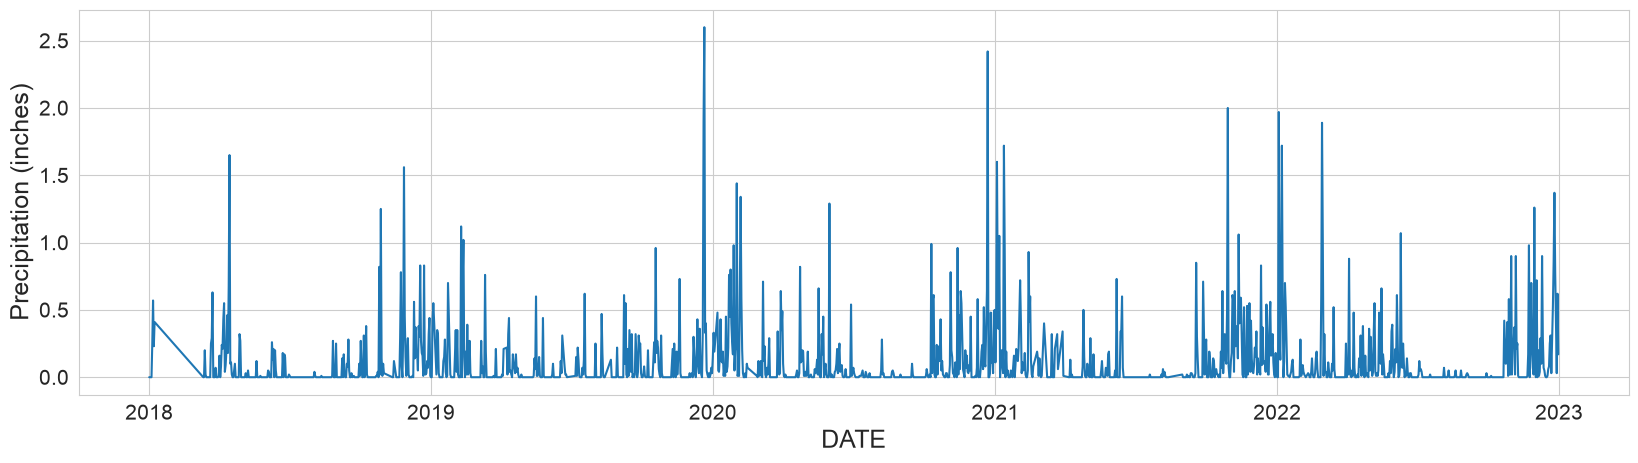

In [478]:
plt.figure(figsize=(20,5))
sns.lineplot(data=df_seattle, x='DATE', y='PRCP')

plt.xlabel('DATE', fontsize=18)
plt.ylabel('Precipitation (inches)', fontsize=18)

plt.tick_params(labelsize=15)

plt.show()

## Daily Precipitation 

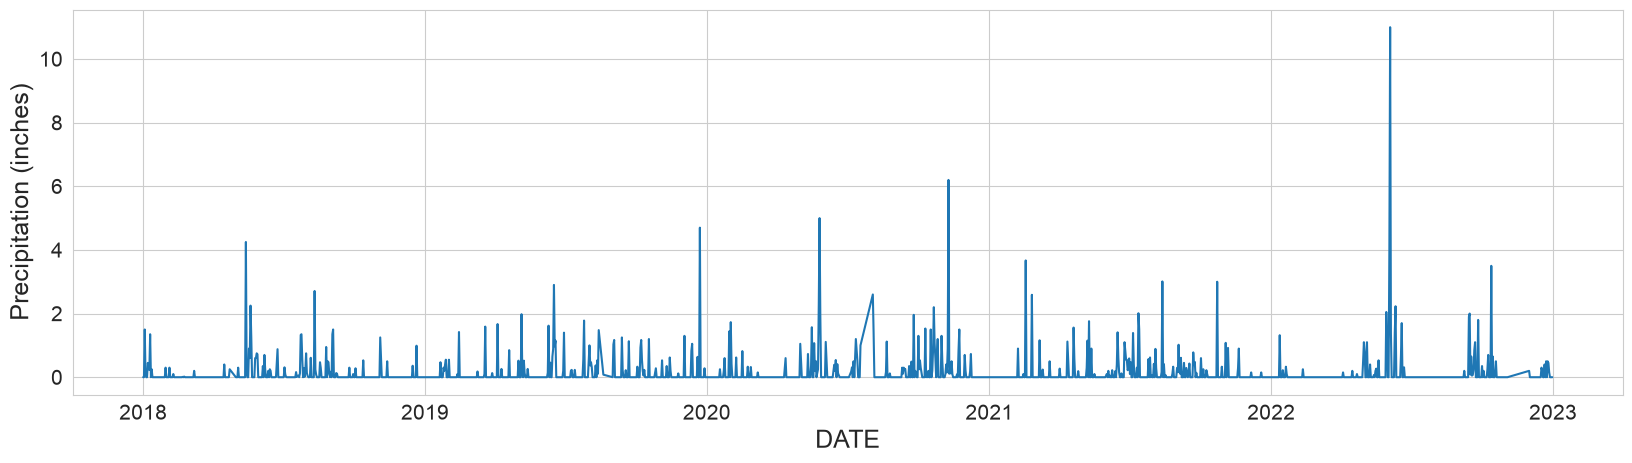

In [480]:
plt.figure(figsize=(20,5))
sns.lineplot(data=df_miami, x='DATE', y='PRCP')

plt.xlabel('DATE', fontsize=18)
plt.ylabel('Precipitation (inches)', fontsize=18)

plt.tick_params(labelsize=15)

plt.show()

In [482]:
df_miami.head()

,STATION,NAME,DATE,DAPR,MDPR,PRCP
0,USW00092811,"MIAMI BEACH, FL US",2018-01-01,NaN,NaN,0.0
1,USW00092811,"MIAMI BEACH, FL US",2018-01-02,NaN,NaN,0.0
2,USW00092811,"MIAMI BEACH, FL US",2018-01-03,NaN,NaN,1.5
3,USW00092811,"MIAMI BEACH, FL US",2018-01-04,NaN,NaN,0.1
4,USW00092811,"MIAMI BEACH, FL US",2018-01-05,NaN,NaN,0.0


In [484]:
df_miami = df_miami.loc[df_miami['DATE'] >= '2018-01-01']

In [485]:
df_miami.head()

,STATION,NAME,DATE,DAPR,MDPR,PRCP
0,USW00092811,"MIAMI BEACH, FL US",2018-01-01,NaN,NaN,0.0
1,USW00092811,"MIAMI BEACH, FL US",2018-01-02,NaN,NaN,0.0
2,USW00092811,"MIAMI BEACH, FL US",2018-01-03,NaN,NaN,1.5
3,USW00092811,"MIAMI BEACH, FL US",2018-01-04,NaN,NaN,0.1
4,USW00092811,"MIAMI BEACH, FL US",2018-01-05,NaN,NaN,0.0


In [486]:
df_miami = df_miami.loc[df_miami['NAME'] == 'MIAMI BEACH, FL US']
df_miami['STATION'].unique()

<ArrowStringArray>
['USW00092811']
Length: 1, dtype: str

In [487]:
df_miami.info()

<class 'pandas.DataFrame'>
RangeIndex: 1598 entries, 0 to 1597
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   STATION  1598 non-null   str           
 1   NAME     1598 non-null   str           
 2   DATE     1598 non-null   datetime64[us]
 3   DAPR     0 non-null      float64       
 4   MDPR     0 non-null      float64       
 5   PRCP     1596 non-null   float64       
dtypes: datetime64[us](1), float64(3), str(2)
memory usage: 120.3 KB


joining data frames keep date and prcp columns

In [489]:
df_seattle.head(2)

,STATION,NAME,DATE,DAPR,MDPR,PRCP,SNOW,SNWD,WESD,WESF
0,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",2018-01-01,NaN,NaN,0.0,NaN,NaN,NaN,NaN
1,US1WAKG0225,"SEATTLE 2.1 ESE, WA US",2018-01-02,NaN,NaN,0.0,NaN,NaN,NaN,NaN


In [490]:
df_miami.head(5)

,STATION,NAME,DATE,DAPR,MDPR,PRCP
0,USW00092811,"MIAMI BEACH, FL US",2018-01-01,NaN,NaN,0.0
1,USW00092811,"MIAMI BEACH, FL US",2018-01-02,NaN,NaN,0.0
2,USW00092811,"MIAMI BEACH, FL US",2018-01-03,NaN,NaN,1.5
3,USW00092811,"MIAMI BEACH, FL US",2018-01-04,NaN,NaN,0.1
4,USW00092811,"MIAMI BEACH, FL US",2018-01-05,NaN,NaN,0.0


outer join

In [492]:
df = df_miami[['DATE','PRCP']].merge(df_seattle[['DATE','PRCP']], on='DATE', how='outer')

In [493]:
df.head()

,DATE,PRCP_x,PRCP_y
0,2018-01-01,0.0,0.00
1,2018-01-02,0.0,0.00
2,2018-01-03,1.5,0.00
3,2018-01-04,0.1,0.00
4,2018-01-05,0.0,0.25


In [494]:
df

,DATE,PRCP_x,PRCP_y
0,2018-01-01,0.00,0.00
1,2018-01-02,0.00,0.00
2,2018-01-03,1.50,0.00
3,2018-01-04,0.10,0.00
4,2018-01-05,0.00,0.25
...,...,...,...
1806,2022-12-27,0.15,0.78
1807,2022-12-28,0.00,0.40
1808,2022-12-29,0.00,0.03
1809,2022-12-30,0.00,0.62


In [495]:
df=pd.melt(df, id_vars='DATE', var_name='city', value_name='precipitation')

In [496]:
df.head()

,DATE,city,precipitation
0,2018-01-01,PRCP_x,0.0
1,2018-01-02,PRCP_x,0.0
2,2018-01-03,PRCP_x,1.5
3,2018-01-04,PRCP_x,0.1
4,2018-01-05,PRCP_x,0.0


In [497]:
df.loc[df['city'] == 'PRCP_x','city'] ='MIA'

In [498]:
df.loc[df['city'] == 'PRCP_y', 'city'] ='SEA'

In [499]:
df.head()

,DATE,city,precipitation
0,2018-01-01,MIA,0.0
1,2018-01-02,MIA,0.0
2,2018-01-03,MIA,1.5
3,2018-01-04,MIA,0.1
4,2018-01-05,MIA,0.0


In [500]:
df.tail()

,DATE,city,precipitation
3617,2022-12-27,SEA,0.78
3618,2022-12-28,SEA,0.40
3619,2022-12-29,SEA,0.03
3620,2022-12-30,SEA,0.62
3621,2022-12-31,SEA,0.17


renaming columns

In [502]:
df = df.rename(columns={'DATE':'date'})

In [503]:
df.head()

,date,city,precipitation
0,2018-01-01,MIA,0.0
1,2018-01-02,MIA,0.0
2,2018-01-03,MIA,1.5
3,2018-01-04,MIA,0.1
4,2018-01-05,MIA,0.0


identify and fill in missing values

In [505]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3622 entries, 0 to 3621
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           3622 non-null   datetime64[us]
 1   city           3622 non-null   str           
 2   precipitation  3232 non-null   float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 95.6 KB


In [506]:
df.notna().sum()

date             3622
city             3622
precipitation    3232
dtype: int64

NULL VALUES?

In [508]:
df.isna().sum()

date               0
city               0
precipitation    390
dtype: int64

number of null values for each city

In [510]:
df.loc[df['city'] == 'SEA', 'precipitation'].isna().sum()

np.int64(175)

In [511]:
df.loc[df['city'] == 'MIA', 'precipitation'].isna().sum()

np.int64(215)

In [512]:
 #impute missing values

In [513]:
#define columns

In [514]:
df['day_of_year'] = pd.DatetimeIndex(df['date']).day_of_year

In [515]:
df.head(10)

,date,city,precipitation,day_of_year
0,2018-01-01,MIA,0.00,1
1,2018-01-02,MIA,0.00,2
2,2018-01-03,MIA,1.50,3
3,2018-01-04,MIA,0.10,4
4,2018-01-05,MIA,0.00,5
5,2018-01-06,MIA,0.00,6
6,2018-01-07,MIA,0.45,7
7,2018-01-08,MIA,0.35,8
8,2018-01-09,MIA,0.23,9
9,2018-01-10,MIA,1.35,10


average mean of prcp for each day in sea, avg across years

In [517]:
mean_day_precipitation = df.loc[
    df['city'] == 'SEA',
    ['precipitation','day_of_year']
    ].groupby(
    'day_of_year'
).mean()

## Mean Precipitation
This plot shows how mean precipitation changes across the days of the year. It helps identify seasonal patterns in precipitation.

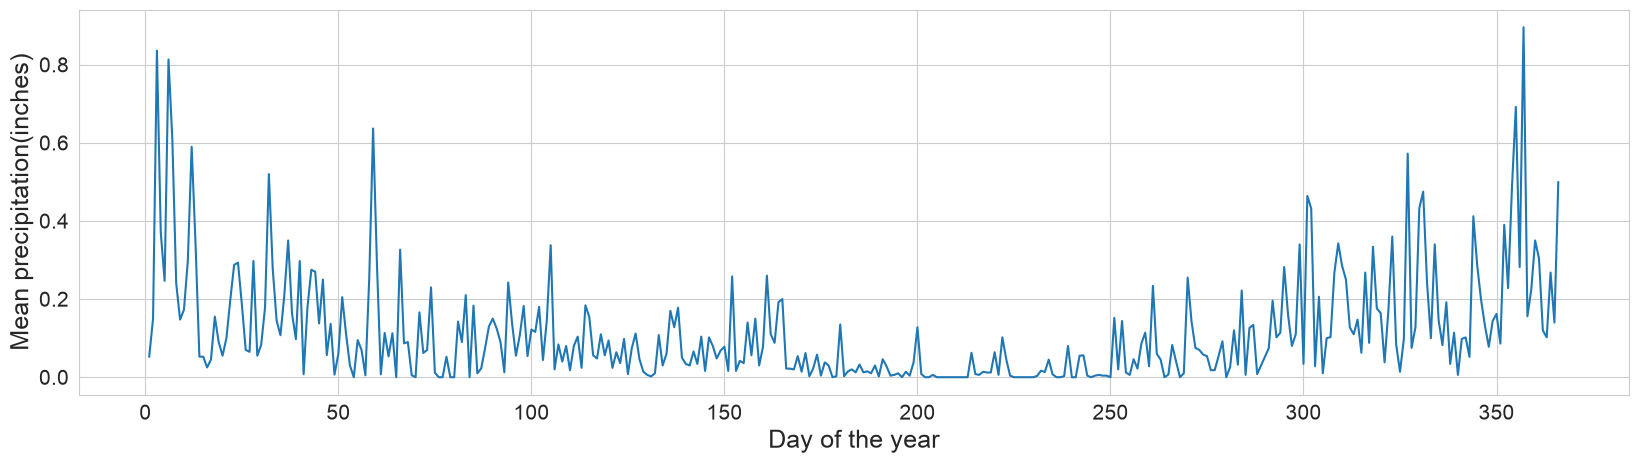

In [519]:
plt.figure(figsize=(20,5))
sns.lineplot(data=mean_day_precipitation, x='day_of_year',y='precipitation')

plt.xlabel('Day of the year', fontsize =18)
plt.ylabel('Mean precipitation(inches)',fontsize=18)

plt.tick_params(labelsize=15)

plt.show()

## The line plot shows periods of the year with higher and lower average precipitation, making it easier to see seasonal trends.

In [521]:
df.head()

,date,city,precipitation,day_of_year
0,2018-01-01,MIA,0.0,1
1,2018-01-02,MIA,0.0,2
2,2018-01-03,MIA,1.5,3
3,2018-01-04,MIA,0.1,4
4,2018-01-05,MIA,0.0,5


In [522]:
df['precipitation'].isna() == True

0       False
1       False
2       False
3       False
4       False
        ...  
3617    False
3618    False
3619    False
3620    False
3621    False
Name: precipitation, Length: 3622, dtype: bool

 index of each row where precipitation is missing

In [524]:
indices = np.where(df['precipitation'].isna() == True)[0]

In [525]:
for index in indices:
    df.loc[index,'precipitation'] = mean_day_precipitation.loc[df.loc[index,'day_of_year']].values[0]

In [526]:
df.isna().sum()

date             0
city             0
precipitation    0
day_of_year      0
dtype: int64

In [527]:
df.to_csv('clean_seattle_miami_weather.csv', encoding='utf-8-sig', index=False)

## This line plot compares precipitation over time between Seattle and Miami. It allows us to see how daily precipitation changes across the study period and identify differences in rainfall patterns between the two cities.

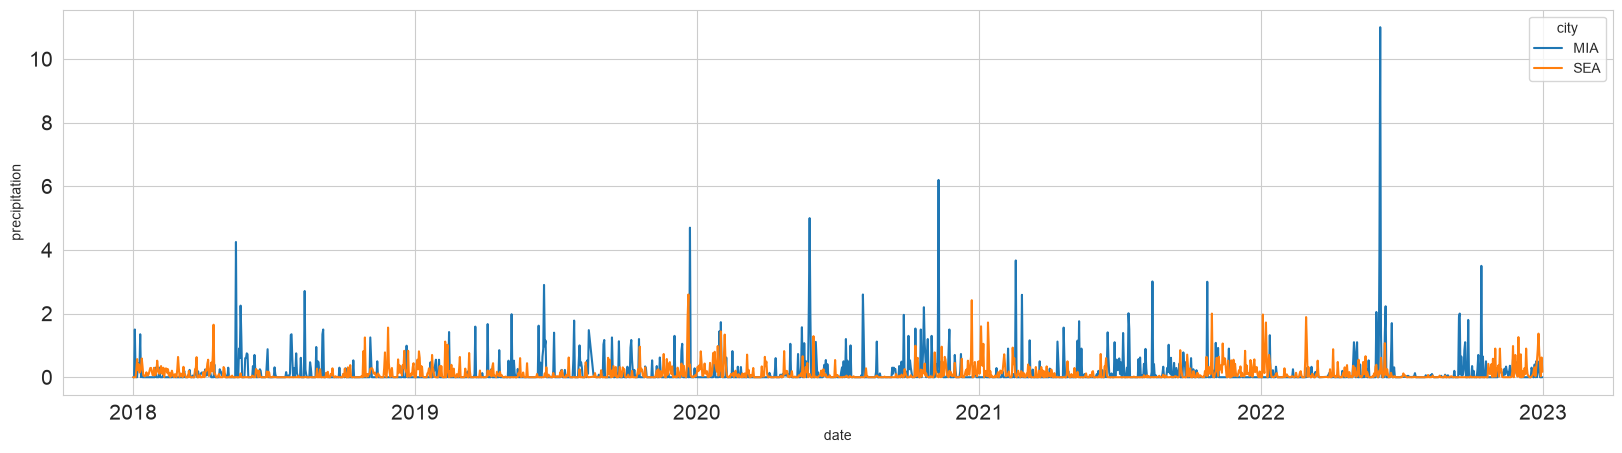

In [529]:
plt.figure(figsize=(20,5))

sns.lineplot(data=df, x='date', y='precipitation', hue='city')

plt.tick_params(labelsize=15)

plt.show()

The plot shows how precipitation varies over time for both cities. It highlights periods of heavier rainfall and allows the precipitation patterns of Seattle and Miami to be compared across the full date range.

 This code allows us to see the count mean standard deviations quartiles and min and max of the rainfall compared to boith cities

In [532]:
df[['city','precipitation']].groupby('city').describe()

precipitation                                                 
             count      mean       std  min  25%   50%    75%   max
city                                                               
MIA         1811.0  0.153928  0.516183  0.0  0.0  0.00  0.055  11.0
SEA         1811.0  0.113643  0.241297  0.0  0.0  0.01  0.120   2.6

The summary statistics allow us to compare the center and spread of precipitation between the two cities. The mean and median show typical precipitation levels, while the standard deviation and maximum values show how variable the precipitation is.

 The code below compares the mean rain fall between the two cities

In [535]:
df[['city','precipitation']].groupby('city').mean()

,precipitation
city,
MIA,0.153928
SEA,0.113643


The results show the average precipitation for each city. Comparing these means helps determine which city receives more precipitation on an average day.

This bar chart compares the mean daily precipitation between Seattle and Miami. It provides a simple visual comparison of which city has higher average daily precipitation.

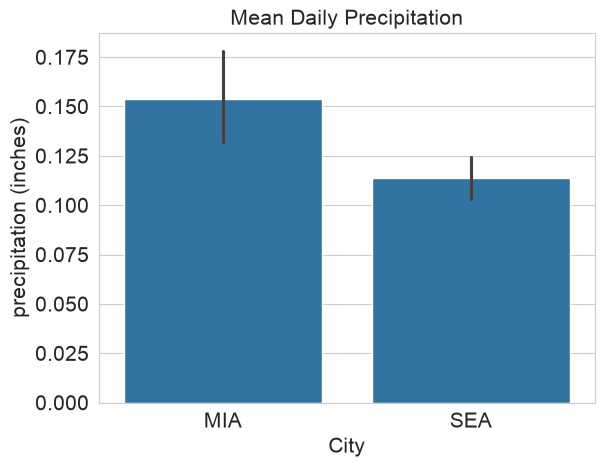

In [538]:
sns.barplot(data=df, x='city', y='precipitation')

plt.ylabel('precipitation (inches)', fontsize=15)
plt.xlabel('City', fontsize=15)
plt.title('Mean Daily Precipitation', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

The height of each bar represents the average daily precipitation for each city. This makes it easier to compare the typical amount of precipitation between Seattle and Miami.

In [615]:
sns.barplot?

Signature:
sns.barplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    order=None,
    hue_order=None,
    estimator='mean',
    errorbar=('ci', 95),
    n_boot=1000,
    seed=None,
    units=None,
    weights=None,
    orient=None,
    color=None,
    palette=None,
    saturation=0.75,
    fill=True,
    hue_norm=None,
    width=0.8,
    dodge='auto',
    gap=0,
    log_scale=None,
    native_scale=False,
    formatter=None,
    legend='auto',
    capsize=0,
    err_kws=None,
    ci=<deprecated>,
    errcolor=<deprecated>,
    errwidth=<deprecated>,
    ax=None,
    **kwargs,
)
Docstring:
Show point estimates and errors as rectangular bars.

A bar plot represents an aggregate or statistical estimate for a numeric
variable with the height of each rectangle and indicates the uncertainty
around that estimate using an error bar. Bar plots include 0 in the
axis range, and they are a good choice when 0 is a meaningful value
for the variable to take.

See the :ref:`tutorial 

In [616]:
#This code extracts the month from each date and stores it in a new month column. This makes it possible to compare precipitation patterns by month.

In [617]:
df['month'] = pd.DatetimeIndex(df['date']).month

In [618]:
df.head()

,date,city,precipitation,day_of_year,month,season,any_precipitation
0,2018-01-01,MIA,0.0,1,1,Winter,False
1,2018-01-02,MIA,0.0,2,1,Winter,False
2,2018-01-03,MIA,1.5,3,1,Winter,True
3,2018-01-04,MIA,0.1,4,1,Winter,True
4,2018-01-05,MIA,0.0,5,1,Winter,False


The dataframe now includes a month number for each observation, which can be used to group and visualize precipitation by month.

In [619]:
#This code checks the unique values in the month column to confirm which months are represented in the dataset.

In [620]:
df['month'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12], dtype=int32)

In [621]:
#The output shows the month numbers present in the data. If all values from 1 through 12 appear, then the dataset includes observations from every month of the year.

This boxplot compares the distribution of daily precipitation by month for Seattle and Miami. It helps visualize seasonal differences in precipitation, including the median, spread, and outliers for each city.

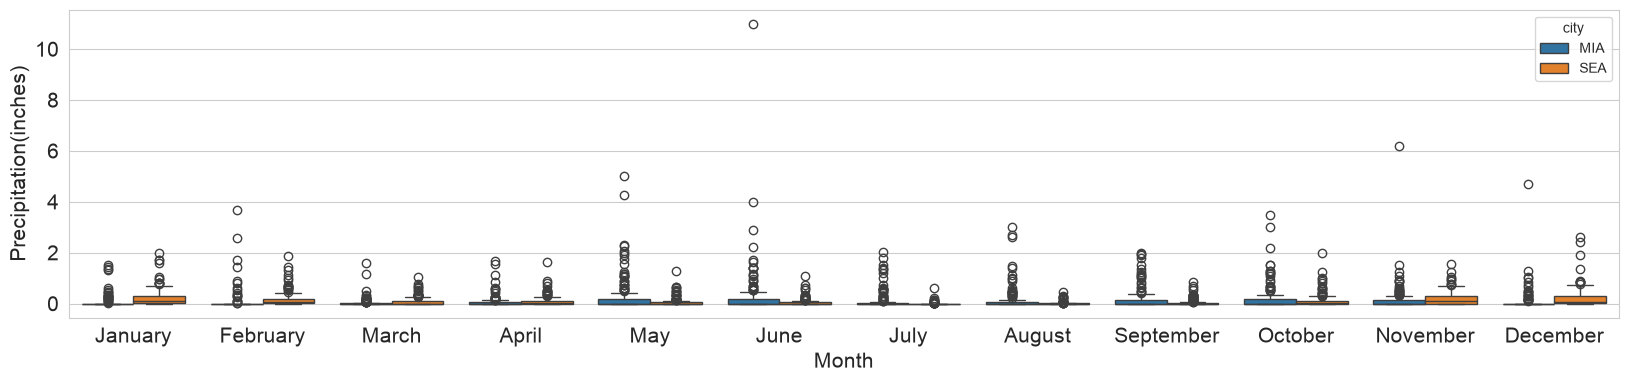

In [622]:
plt.figure(figsize=(20,4))

sns.boxplot(data=df, x='month', y='precipitation', hue='city')

plt.xlabel('Month', fontsize=15)
plt.ylabel('Precipitation(inches)',fontsize=15)

plt.tick_params(labelsize=15)

#Get month names and set as x-axis tick labels
import calendar
month_names = list(calendar.month_name[1:]) # to get month names
plt.xticks(ticks=range(12), labels=month_names) # Set x-acis ticks to month names

plt.show()

The boxplots show how daily precipitation varies across months in each city. They make it easier to compare seasonal patterns, typical precipitation levels, and the variability of rainfall between Seattle and Miami.

This horizontal boxplot compares the distribution of daily precipitation by month for Seattle and Miami. It helps show seasonal differences in the median, spread, and outliers of precipitation.

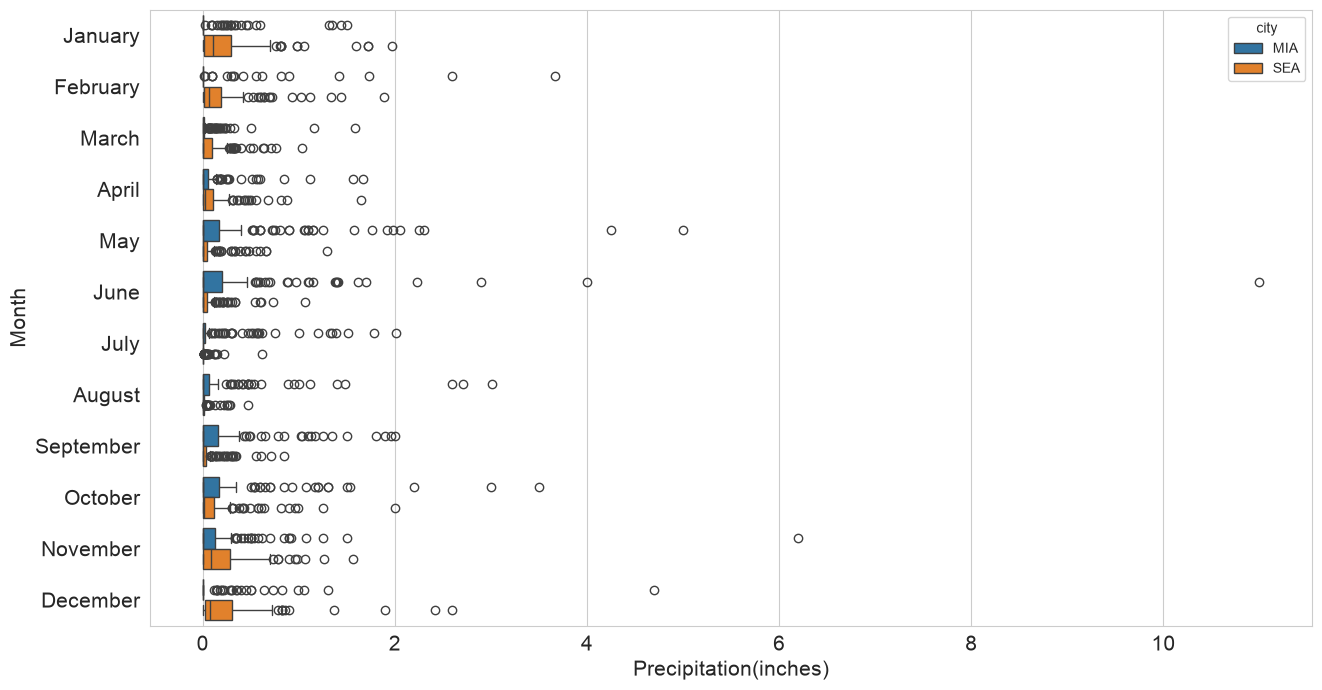

In [623]:
plt.figure(figsize=(15,8))

sns.boxplot(data=df, x='precipitation', y='month', hue='city', orient='h')

plt.ylabel('Month', fontsize=15)
plt.xlabel('Precipitation(inches)',fontsize=15)

plt.tick_params(labelsize=15)

#Get month names and set as x-axis tick labels
import calendar
month_names = list(calendar.month_name[1:]) # to get month names
plt.yticks(ticks=range(12), labels=month_names) # Set x-acis ticks to month names

plt.show()

The horizontal boxplots make it easier to compare precipitation distributions across months and between the two cities, highlighting seasonal patterns and unusually high precipitation values.

This boxplot compares the distribution of daily precipitation by month for Seattle and Miami. The y-axis is limited to 0.4 inches to make the typical precipitation patterns easier to compare across months.

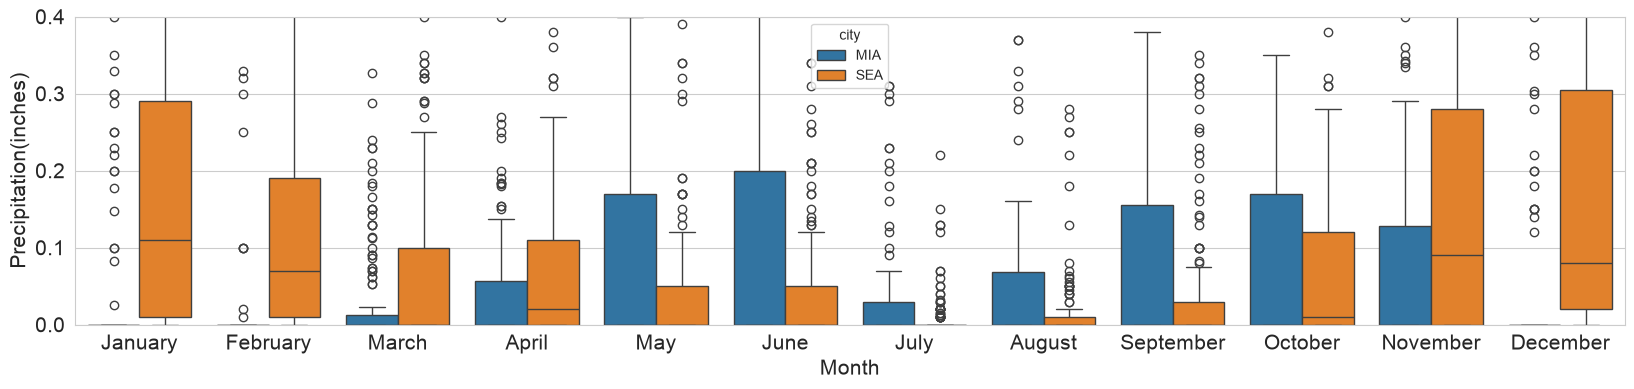

In [624]:
plt.figure(figsize=(20,4))

sns.boxplot(data=df, x='month', y='precipitation', hue='city')

plt.xlabel('Month', fontsize=15)
plt.ylabel('Precipitation(inches)',fontsize=15)

plt.tick_params(labelsize=15)

#Get month names and set as x-axis tick labels
import calendar
month_names = list(calendar.month_name[1:]) # to get month names
plt.xticks(ticks=range(12), labels=month_names) # Set x-acis ticks to month names

plt.ylim(0,0.4)

plt.show()

The plot shows differences in the median and spread of daily precipitation across months for both cities. Limiting the y-axis makes the central patterns easier to see, although precipitation values above 0.4 inches are not displayed.

This bar chart compares the mean daily precipitation for Seattle and Miami across each month of the year. It helps show how average precipitation changes seasonally and how the two cities differ by month.

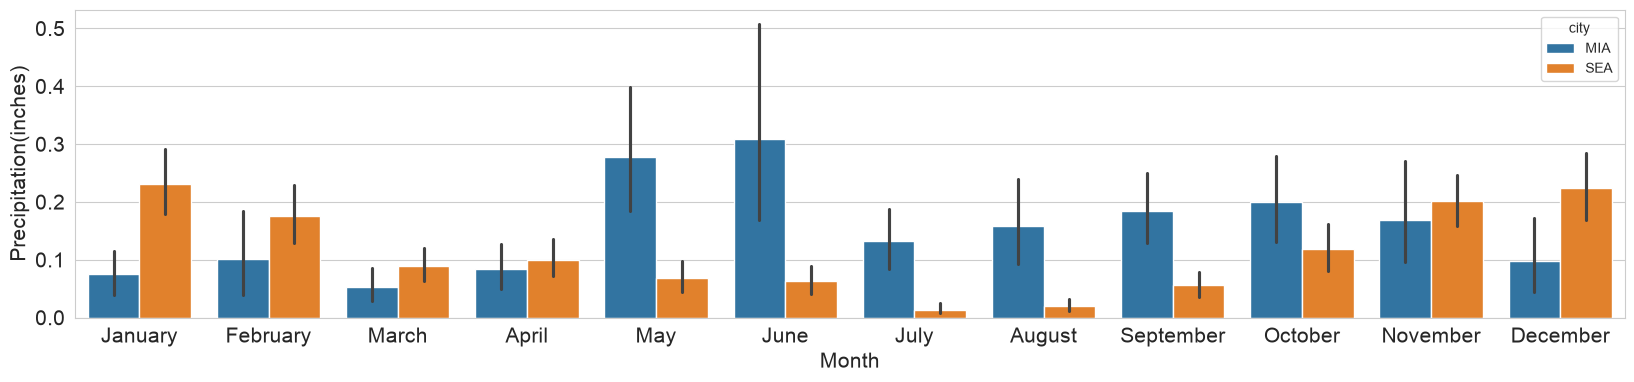

In [625]:
plt.figure(figsize=(20,4))

sns.barplot(data=df, x='month', y='precipitation', hue='city')

plt.xlabel('Month', fontsize=15)
plt.ylabel('Precipitation(inches)',fontsize=15)

plt.tick_params(labelsize=15)

#Get month names and set as x-axis tick labels
import calendar
month_names = list(calendar.month_name[1:]) # to get month names
plt.xticks(ticks=range(12), labels=month_names) # Set x-acis ticks to month names

plt.show()

In [626]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['season'] = df['month'].apply(get_season)

In [627]:
df[['month', 'season']].head(12)

,month,season
0,1,Winter
1,1,Winter
2,1,Winter
3,1,Winter
4,1,Winter
5,1,Winter
6,1,Winter
7,1,Winter
8,1,Winter
9,1,Winter


In [628]:
df['month'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12], dtype=int32)

In [629]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['season'] = df['month'].apply(get_season)

In [630]:
df[['month', 'season']].drop_duplicates().sort_values('month')

,month,season
0,1,Winter
31,2,Winter
59,3,Spring
90,4,Spring
120,5,Spring
151,6,Summer
181,7,Summer
212,8,Summer
243,9,Fall
273,10,Fall


Box plot that shows average precipitation for each season

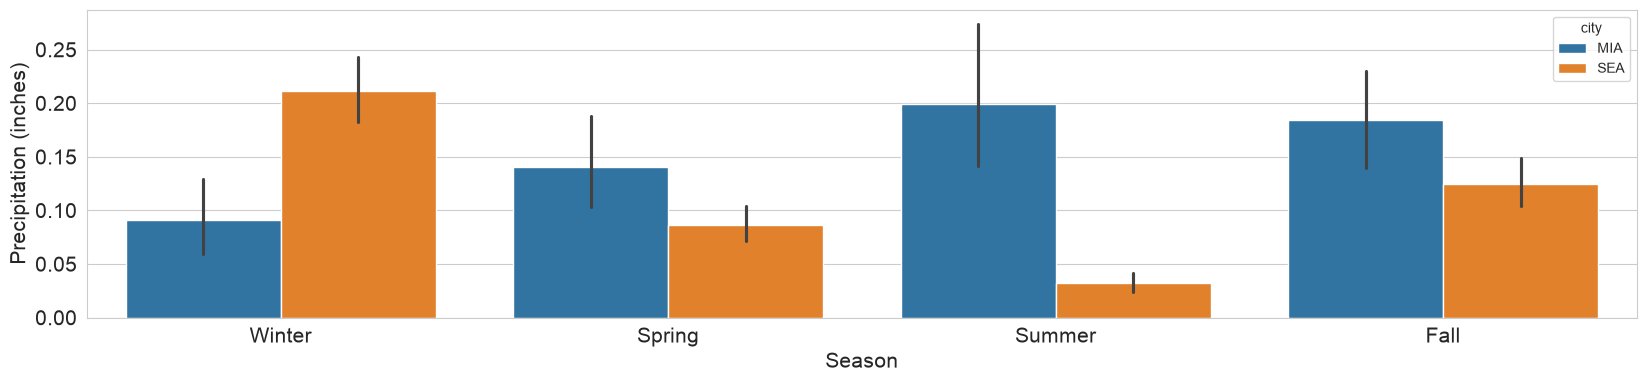

In [631]:
season_order = ['Winter', 'Spring', 'Summer', 'Fall']

plt.figure(figsize=(20,4))

sns.barplot(
    data=df,
    x='season',
    y='precipitation',
    hue='city',
    order=season_order
)

plt.xlabel('Season', fontsize=15)
plt.ylabel('Precipitation (inches)', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

In [632]:
df.columns

Index(['date', 'city', 'precipitation', 'day_of_year', 'month', 'season',
       'any_precipitation'],
      dtype='str')

The chart shows the average daily precipitation for each month in both cities. Comparing the bar heights makes it easier to identify which months have higher average precipitation and how seasonal patterns differ between Seattle and Miami.

In [633]:
 df[['month', 'precipitation', 'city']].groupby(['city','month']).mean()

precipitation
city month               
MIA  1           0.075032
     2           0.101064
     3           0.052725
     4           0.083327
     5           0.277239
     6           0.308650
     7           0.132561
     8           0.158771
     9           0.184910
     10          0.200129
     11          0.168480
     12          0.098026
SEA  1           0.230742
     2           0.176472
     3           0.089920
     4           0.100483
     5           0.069161
     6           0.063167
     7           0.013984
     8           0.020639
     9           0.055622
     10          0.118452
     11          0.200923
     12          0.224903

This code creates a new variable called any_precipitation that indicates whether precipitation occurred on each day. Days with precipitation greater than zero are labeled True, while days with no precipitation are labeled False.

In [634]:
 df[['month', 'precipitation', 'city']].groupby(['city','month']).max()

precipitation
city month               
MIA  1               1.50
     2               3.67
     3               1.59
     4               1.67
     5               5.00
     6              11.00
     7               2.01
     8               3.01
     9               2.00
     10              3.50
     11              6.20
     12              4.70
SEA  1               1.97
     2               1.89
     3               1.03
     4               1.65
     5               1.29
     6               1.07
     7               0.62
     8               0.47
     9               0.85
     10              2.00
     11              1.56
     12              2.60

In [635]:
df['any_precipitation'] = df['precipitation']>0
df.head()

,date,city,precipitation,day_of_year,month,season,any_precipitation
0,2018-01-01,MIA,0.0,1,1,Winter,False
1,2018-01-02,MIA,0.0,2,1,Winter,False
2,2018-01-03,MIA,1.5,3,1,Winter,True
3,2018-01-04,MIA,0.1,4,1,Winter,True
4,2018-01-05,MIA,0.0,5,1,Winter,False


The output confirms that the new any_precipitation column was added successfully and can be used to compare the proportion of rainy days between the two cities.

The code below chart compares the proportion of days with precipitation in Seattle and Miami for each month. It helps show how often precipitation occurs throughout the year in each city.

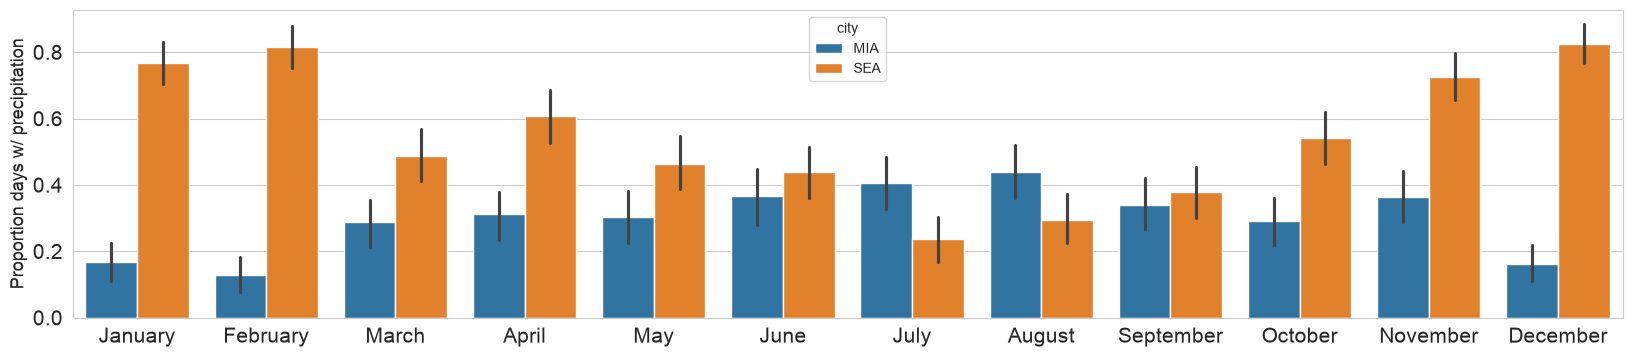

In [636]:
plt.figure(figsize=(20, 4))

sns.barplot(data=df, x='month', y='any_precipitation', hue='city')

plt.xlabel(None)
plt.ylabel('Proportion days w/ precipitation', fontsize=13)
plt.xticks(ticks=range(12), labels=month_names)
plt.tick_params(labelsize=15)

plt.show()

The chart shows how the frequency of precipitation changes by month for both cities. Higher bars indicate months with a greater proportion of days that experienced precipitation, making seasonal differences between Seattle and Miami easier to compare.

The code below ompares mean precipitation by month for Seattle and Miami. It helps show seasonal trends and how average precipitation changes throughout the year in each city.

<Axes: xlabel='month', ylabel='precipitation'>

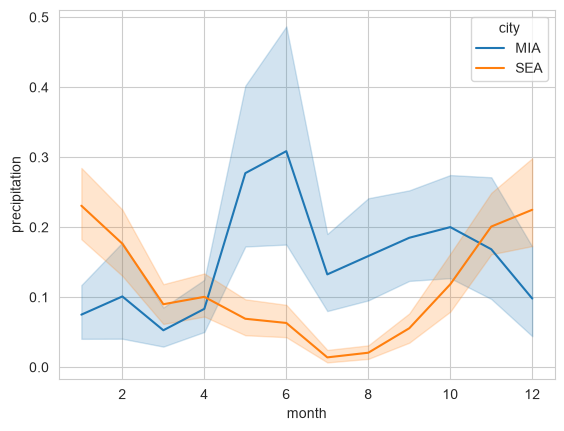

In [637]:
sns.lineplot(
    data=df,
    x='month',
    y='precipitation',
    hue='city'
)

The lines show how average precipitation changes from month to month for both cities. This makes it easier to compare seasonal rainfall patterns and identify times of year when one city tends to receive more precipitation than the other.

The code compares the distribution of daily precipitation between Seattle and Miami. It helps show differences in the median, spread, and unusually high precipitation values for each city.

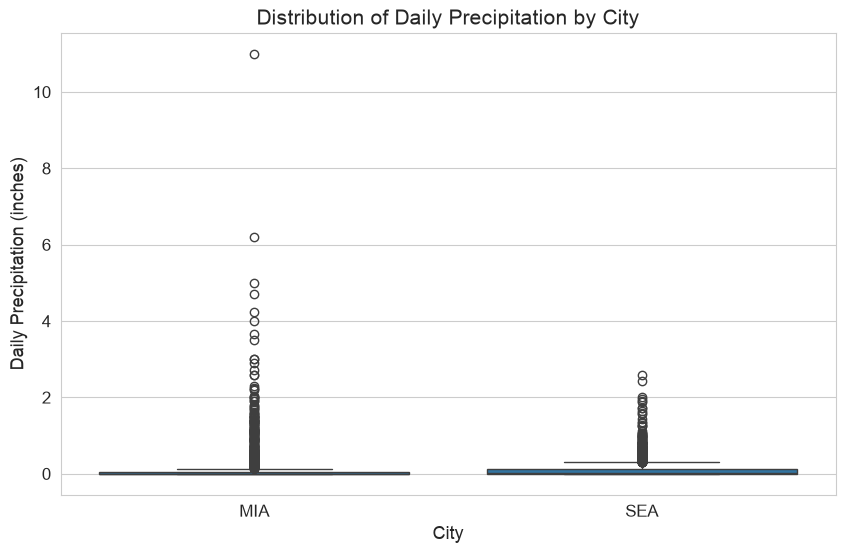

In [638]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='city', y='precipitation')

plt.xlabel('City', fontsize=13)
plt.ylabel('Daily Precipitation (inches)', fontsize=13)
plt.title('Distribution of Daily Precipitation by City', fontsize=15)
plt.tick_params(labelsize=12)

plt.show()

The boxplot shows how daily precipitation is distributed in each city. It allows the typical precipitation level, variability, and outliers to be compared between Seattle and Miami.

The code below creates a  violin plot and compares the distribution of daily precipitation between Seattle and Miami. It shows both the spread of precipitation values and where observations are most concentrated.

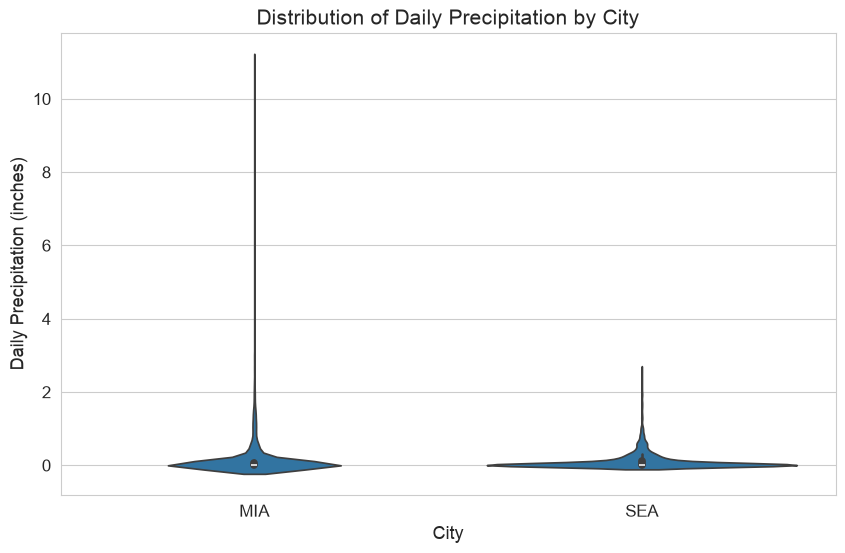

In [639]:
plt.figure(figsize=(10, 6))

sns.violinplot(data=df, x='city', y='precipitation')

plt.xlabel('City', fontsize=13)
plt.ylabel('Daily Precipitation (inches)', fontsize=13)
plt.title('Distribution of Daily Precipitation by City', fontsize=15)

plt.tick_params(labelsize=12)

plt.show()

The violin plot shows how daily precipitation values are distributed for each city. Wider portions of the plot represent precipitation amounts that occur more frequently, making it easier to compare the overall shape and variability of precipitation between Seattle and Miami.

The code below creates a histogram that compares the distribution of daily precipitation in January for Seattle and Miami. It shows how frequently different precipitation amounts occur in each city during the month

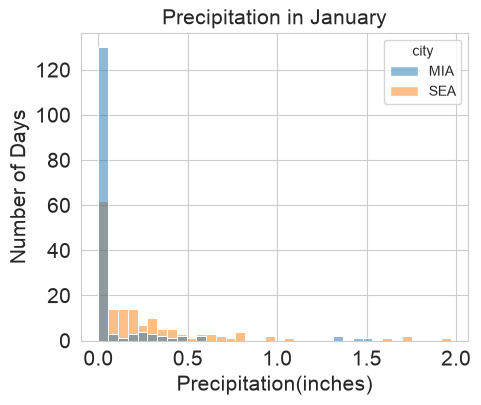

In [640]:
plt.figure(figsize=(5, 4))

sns.histplot(data=df.loc[df['month'] == 1], x='precipitation', hue='city')

plt.xlabel('Precipitation(inches)', fontsize=15)
plt.ylabel('Number of Days', fontsize=15)
plt.title('Precipitation in January', fontsize=15)

plt.tick_params(labelsize=15)

plt.show()

 The histogram shows the frequency of different daily precipitation amounts in January for both cities. It helps compare the shape of the distributions and identify whether one city experiences precipitation more often or at higher amounts during January.

In [641]:
from scipy import stats

In [642]:
# the code will create an analysis that uses independent two-sample t-tests to compare mean daily precipitation between Seattle and Miami for each month. A significance level of 0.05 is used to determine whether the difference in mean precipitation is statistically significant.

In [643]:
significance_level = 0.05
significantly_different = np.zeros(12)

for month in range(1,13):
    sea_data = df.loc[(df['city'] == 'SEA') & (df['month'] == month), 'precipitation']
    mia_data = df.loc[(df['city'] == 'MIA') & (df['month'] == month), 'precipitation']

    t_statistic, p_value = stats.ttest_ind(sea_data, mia_data, equal_var=False)

    if p_value < significance_level:
        significantly_different[month-1] = 1 

    print(f"Month{month}:")
    print(f" t-statistic = {t_statistic:.2f}")
    print(f" p value t test = {p_value:.3f}")
    print("-" *20)


Month1:
 t-statistic = 4.62
 p value t test = 0.000
--------------------
Month2:
 t-statistic = 1.70
 p value t test = 0.090
--------------------
Month3:
 t-statistic = 1.83
 p value t test = 0.068
--------------------
Month4:
 t-statistic = 0.68
 p value t test = 0.499
--------------------
Month5:
 t-statistic = -3.62
 p value t test = 0.000
--------------------
Month6:
 t-statistic = -2.87
 p value t test = 0.005
--------------------
Month7:
 t-statistic = -4.19
 p value t test = 0.000
--------------------
Month8:
 t-statistic = -3.70
 p value t test = 0.000
--------------------
Month9:
 t-statistic = -3.65
 p value t test = 0.000
--------------------
Month10:
 t-statistic = -1.79
 p value t test = 0.075
--------------------
Month11:
 t-statistic = 0.63
 p value t test = 0.528
--------------------
Month12:
 t-statistic = 2.78
 p value t test = 0.006
--------------------


The t-tests compare the mean precipitation between Seattle and Miami separately for each month. Months with a p-value below 0.05 are considered statistically significant, meaning the data provide evidence that the average precipitation differs between the two cities during those months.

Code creates a  chart compares the proportion of days with precipitation in Seattle and Miami for each month. Asterisks mark months where the difference between the cities is statistically significant based on a two-proportion z-test.

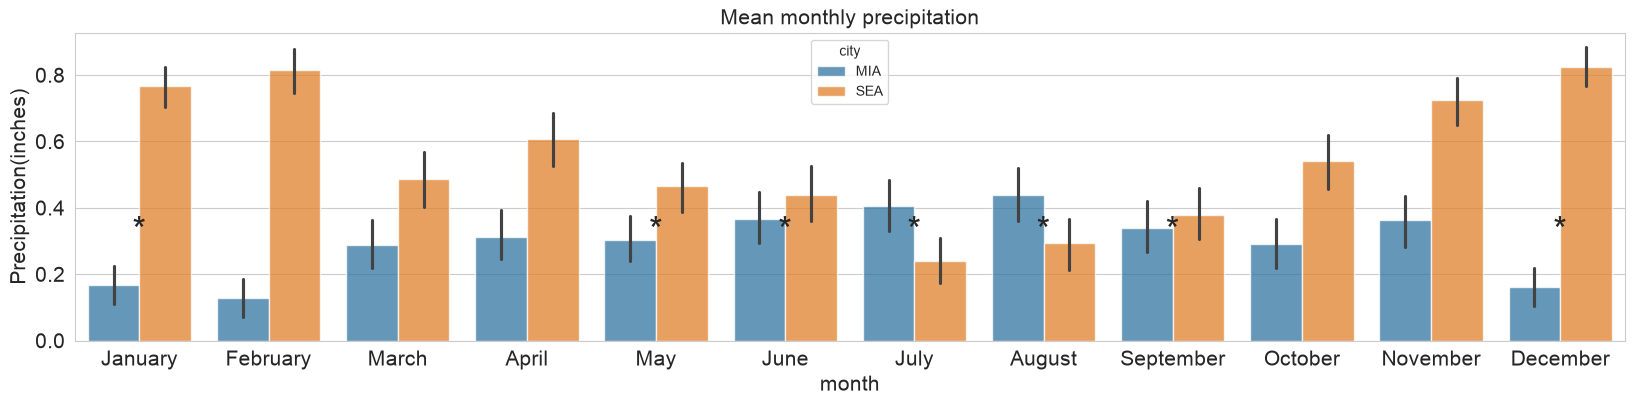

In [644]:
plt.figure(figsize=(20, 4))

sns.barplot(data=df, x='month', y='any_precipitation', hue='city', alpha=0.75)

plt.xlabel('month', fontsize=15)
plt.ylabel('Precipitation(inches)', fontsize=15)
plt.title('Mean monthly precipitation', fontsize=15)

plt.xticks(ticks=range(12), labels=month_names)

plt.tick_params(labelsize=15)

for month in range(12):
    if significantly_different[month] == 1:
        plt.text(month, 0.3, '*', ha='center', fontsize=25)

plt.show()

The graph shows how frequently precipitation occurs in each city throughout the year. Higher bars indicate a greater proportion of days with precipitation, and the asterisks identify months where the difference between Seattle and Miami is statistically significant.

The code will create an  analysis that  uses a two-proportion z-test to compare the proportion of days with precipitation between Seattle and Miami for each month. A significance level of 0.05 is used to determine whether the difference in precipitation frequency between the two cities is statistically significant.

In [645]:
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3622 entries, 0 to 3621
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               3622 non-null   datetime64[us]
 1   city               3622 non-null   str           
 2   precipitation      3622 non-null   float64       
 3   day_of_year        3622 non-null   int32         
 4   month              3622 non-null   int32         
 5   season             3622 non-null   str           
 6   any_precipitation  3622 non-null   bool          
dtypes: bool(1), datetime64[us](1), float64(1), int32(2), str(2)
memory usage: 175.2 KB


In [646]:
from statsmodels.stats.proportion import proportions_ztest

significance_level = 0.05
significantly_different_proportion = np.zeros(12)

for month in range(1, 13):

    contingency_table = pd.crosstab(
        df.loc[df['month'] == month, 'city'],
        df.loc[df['month'] == month, 'any_precipitation']
    )

    days_with_precipitation = contingency_table[True]
    total_counts = contingency_table.sum(axis=1)

    zstat, p_value = proportions_ztest(
        count=days_with_precipitation,
        nobs=total_counts,
        alternative='two-sided'
    )

    if p_value < significance_level:
        significantly_different_proportion[month - 1] = 1

        print(f"Month {month}:")
        print(f"z-statistic = {zstat:.2f}")
        print(f"p-value = {p_value:.3f}")
        print("-" * 20)

Month 1:
z-statistic = -10.59
p-value = 0.000
--------------------
Month 2:
z-statistic = -11.57
p-value = 0.000
--------------------
Month 3:
z-statistic = -3.48
p-value = 0.000
--------------------
Month 4:
z-statistic = -5.10
p-value = 0.000
--------------------
Month 5:
z-statistic = -2.92
p-value = 0.004
--------------------
Month 7:
z-statistic = 3.16
p-value = 0.002
--------------------
Month 8:
z-statistic = 2.64
p-value = 0.008
--------------------
Month 10:
z-statistic = -4.49
p-value = 0.000
--------------------
Month 11:
z-statistic = -6.28
p-value = 0.000
--------------------
Month 12:
z-statistic = -11.70
p-value = 0.000
--------------------


## The z-tests identify the months in which Seattle and Miami have significantly different proportions of days with precipitation. Months with a p-value below 0.05 are considered statistically significant and are stored in the significantly_different_proportion array for use in later visualizations.

## This code creates a  contingency table that summarizes the number of January days with and without precipitation for each city. It is used to compare precipitation frequency between Seattle and Miami.

In [647]:
contigency_table = pd.crosstab(
    df.loc[df['month'] == 1, 'city'], df.loc[df['month'] == 1, 'any_precipitation']
        )
contigency_table

any_precipitation,False,True
city,,
MIA,129,26
SEA,36,119


## The table shows the counts of dry days and precipitation days for each city in January. These counts can be used in a two-proportion z-test to determine whether the proportion of precipitation days differs significantly between the cities.

In [648]:
days_with_precipitation = contingency_table[True]
days_with_precipitation

city
MIA     25
SEA    128
Name: True, dtype: int64

## Results

To compare rainfall patterns between Seattle and Miami, I used Welch's two sample t- test to assess differences in mean daily precipitation by month. Two proportion z tests were used to compare the proportion of days with precipitation between the two cities.

The t-tests showed statistically significant differences in mean daily precipitation in the months of January, May, June, July, August, September, and December. Seattle had greater mean precipitation in January and December, while Miami showed to have greater mean precipitation from May through September. No statistically significant difference was found in the months of February, March, April, October, or November. 

The two-proportion z-tests suggests that the frequency of precipitation also was different between the 2 cities during most months. Seattle ultimately experienced precipitation on more days during year, while Miami tended to recieve larger amounts of precipitation in the wetter months. 

The results suggest that rainfall differs between the two cities in both amount and frequency. 

## Conclusion

Results prove that whether it rains more in Seattle vs Miami depends on how rainfall is measured. Seattle experiences precipitation at higher frequency much of the year, mostly during the cooler months. Miami, however, tends to receive greater amounts of precipitation during late spring and summer. 

Essentially, Seattle can technically be considered rainier in terms of how often it rains, while Miami can receive more rainfall in terms of the amount of precipitation.

